In [1]:
import os
import librosa
import numpy as np
import torch
from tqdm import tqdm

# Cấu hình
input_dir = "nuhive_processed"
output_dir = "mel_spectrograms"
os.makedirs(output_dir, exist_ok=True)

labels = ["bee", "nobee", "noqueen"]
sample_rate = 22050
n_fft = 2048
hop_length = 512
n_mels = 64
power = 2

# Tạo Log-Mel Spectrogram (không chuyển sang dB)
def wav_to_log_mel(wav_path):
    y, sr = librosa.load(wav_path, sr=sample_rate)
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=power
    )
    # Log (natural log) - không dùng librosa.power_to_db
    log_mel = np.log(mel_spec + 1e-9)  # tránh log(0)
    return torch.tensor(log_mel, dtype=torch.float32)

# Duyệt qua các thư mục và lưu tensor
for label in labels:
    label_dir = os.path.join(input_dir, label)
    if not os.path.exists(label_dir):
        continue
    wav_files = [f for f in os.listdir(label_dir) if f.endswith('.wav')]
    for i, wav_file in enumerate(tqdm(wav_files, desc=f"Processing {label}")):
        wav_path = os.path.join(label_dir, wav_file)
        log_mel_tensor = wav_to_log_mel(wav_path)
        save_path = os.path.join(output_dir, f"{label}_{i}.pt")
        torch.save(log_mel_tensor, save_path)

print("✅ Đã lưu tất cả Log-Mel Spectrogram vào thư mục mel_spectrograms")

Processing noqueen: 100%|██████████| 4861/4861 [00:22<00:00, 220.51it/s]

✅ Đã lưu tất cả Log-Mel Spectrogram vào thư mục mel_spectrograms


In [2]:
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
import os
import numpy as np

class MelSpectrogramDataset(Dataset):
    def __init__(self, data_dir):
        self.data_dir = data_dir
        self.files = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        self.label_map = {"bee": 0, "nobee": 1, "noqueen": 2}
    
    def __len__(self):
        return len(self.files)
    
    def __getitem__(self, idx):
        file_name = self.files[idx]
        tensor = torch.load(os.path.join(self.data_dir, file_name))
        # Thêm chiều channel nếu cần (1, H, W)
        tensor = tensor.unsqueeze(0)  # shape: (1, n_mels, time)
        label_str = file_name.split('_')[0]
        label = self.label_map[label_str]
        return tensor, label

# Tạo dataset
dataset = MelSpectrogramDataset("mel_spectrograms")

# Lấy labels để stratify
labels = []
for f in dataset.files:
    label_str = f.split('_')[0]
    labels.append(dataset.label_map[label_str])

# Stratified split
indices = list(range(len(dataset)))
train_idx, temp_idx, _, temp_labels = train_test_split(
    indices, labels, test_size=0.3, stratify=labels, random_state=42
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, stratify=temp_labels, random_state=42
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

# DataLoader
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 9654, Val: 2069, Test: 2069


In [3]:
import torch.nn as nn
import torch.nn.functional as F

class DCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(DCNN, self).__init__()
        # Input: (batch, 1, 64, T)
        self.conv1 = nn.Conv2d(1, 32, kernel_size=(3, 3), padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=(3, 3), padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=(3, 3), padding=1)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=(3, 3), padding=1)
        self.conv5 = nn.Conv2d(256, 512, kernel_size=(3, 3), padding=1)
        
        self.pool = nn.AdaptiveAvgPool2d((4, 4))  # cố định kích thước đầu ra
        self.fc = nn.Linear(512 * 4 * 4, num_classes)
        self.dropout = nn.Dropout(0.5)
        
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, (2, 2))
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, (2, 2))
        x = F.relu(self.conv3(x))
        x = F.max_pool2d(x, (2, 2))
        x = F.relu(self.conv4(x))
        x = F.max_pool2d(x, (2, 2))
        x = F.relu(self.conv5(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# Kiểm tra mô hình
model = DCNN()
print(model)

DCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc): Linear(in_features=8192, out_features=3, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


In [4]:
import torch
from tqdm import tqdm
from sklearn.metrics import f1_score
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DCNN().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

# Lưu lịch sử
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': [],
    'train_f1': [], 'val_f1': []
}

num_epochs = 30
best_f1 = 0.0
best_model_wts = None

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 30)
    
    # --- Training ---
    model.train()
    train_loss = 0.0
    train_preds, train_labels = [], []
    
    for inputs, labels in tqdm(train_loader, desc="Training"):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        train_preds.extend(preds.cpu().numpy())
        train_labels.extend(labels.cpu().numpy())
    
    # --- Validation ---
    model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    
    with torch.no_grad():
        for inputs, labels in tqdm(val_loader, desc="Validation"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())
    
    # Tính metrics
    train_acc = np.mean(np.array(train_preds) == np.array(train_labels))
    val_acc = np.mean(np.array(val_preds) == np.array(val_labels))
    train_f1 = f1_score(train_labels, train_preds, average='weighted')
    val_f1 = f1_score(val_labels, val_preds, average='weighted')
    
    train_loss /= len(train_dataset)
    val_loss /= len(val_dataset)
    
    # Lưu lịch sử
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['train_f1'].append(train_f1)
    history['val_f1'].append(val_f1)
    
    print(f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f}, F1: {train_f1:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}, F1: {val_f1:.4f}")
    
    # Lưu mô hình tốt nhất theo F1
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_model_wts = copy.deepcopy(model.state_dict())

# Tải lại mô hình tốt nhất
model.load_state_dict(best_model_wts)
print("✅ Huấn luyện hoàn tất. Đã tải trọng số tốt nhất.")


Epoch 1/30
------------------------------


Validation: 100%|██████████| 65/65 [00:57<00:00,  1.13it/s]


Train Loss: 0.8296, Acc: 0.6167, F1: 0.5996
Val Loss: 0.6859, Acc: 0.7206, F1: 0.7038

Epoch 2/30
------------------------------


Validation: 100%|██████████| 65/65 [00:00<00:00, 89.27it/s]


Train Loss: 0.5925, Acc: 0.7612, F1: 0.7459
Val Loss: 0.5994, Acc: 0.7675, F1: 0.7519

Epoch 3/30
------------------------------


...

Train Loss: 0.2083, Acc: 0.9128, F1: 0.9111
Val Loss: 0.5404, Acc: 0.8304, F1: 0.8210

Epoch 29/30
------------------------------


Validation: 100%|██████████| 65/65 [00:00<00:00, 86.92it/s]


Train Loss: 0.2093, Acc: 0.9157, F1: 0.9141
Val Loss: 0.4659, Acc: 0.8458, F1: 0.8396

Epoch 30/30
------------------------------


Validation: 100%|██████████| 65/65 [00:00<00:00, 86.39it/s]

Train Loss: 0.1701, Acc: 0.9302, F1: 0.9292
Val Loss: 0.5381, Acc: 0.8439, F1: 0.8395
✅ Huấn luyện hoàn tất. Đã tải trọng số tốt nhất.


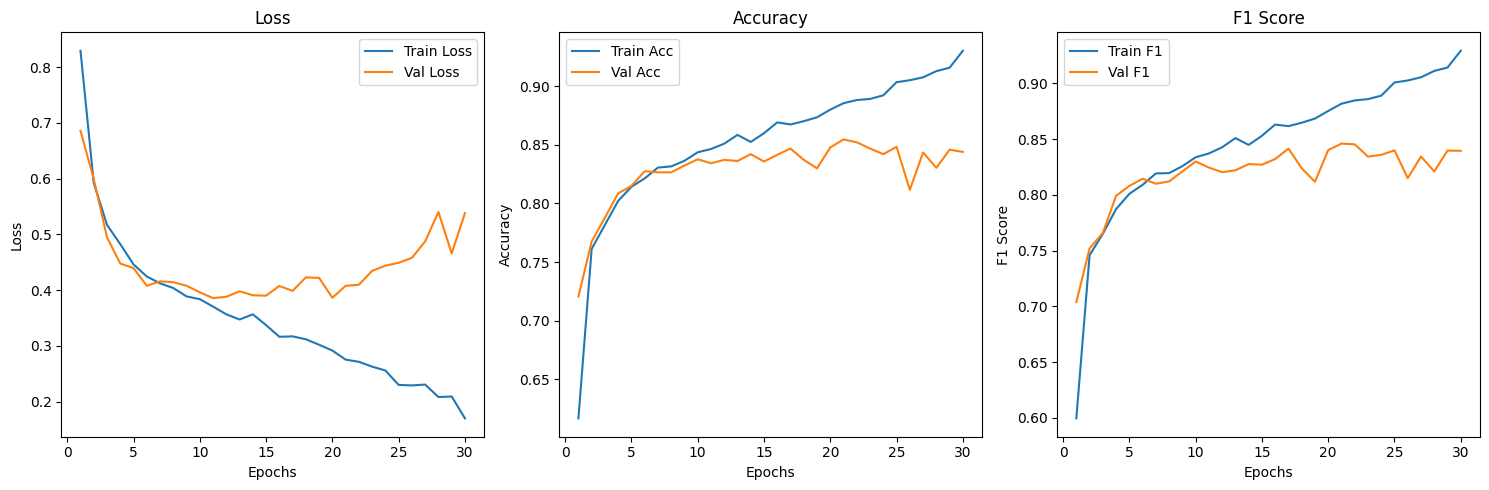

In [5]:
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(15, 5))

# Loss
plt.subplot(1, 3, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss')
plt.plot(epochs, history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy
plt.subplot(1, 3, 2)
plt.plot(epochs, history['train_acc'], label='Train Acc')
plt.plot(epochs, history['val_acc'], label='Val Acc')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# F1 Score
plt.subplot(1, 3, 3)
plt.plot(epochs, history['train_f1'], label='Train F1')
plt.plot(epochs, history['val_f1'], label='Val F1')
plt.title('F1 Score')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()

plt.tight_layout()
plt.show()

Testing: 100%|██████████| 65/65 [01:05<00:00,  1.01s/it]

Classification Report:
              precision    recall  f1-score   support

         bee       0.87      0.94      0.90       821
       nobee       0.79      0.51      0.62       519
     noqueen       0.83      0.96      0.89       729

    accuracy                           0.84      2069
   macro avg       0.83      0.80      0.80      2069
weighted avg       0.83      0.84      0.83      2069



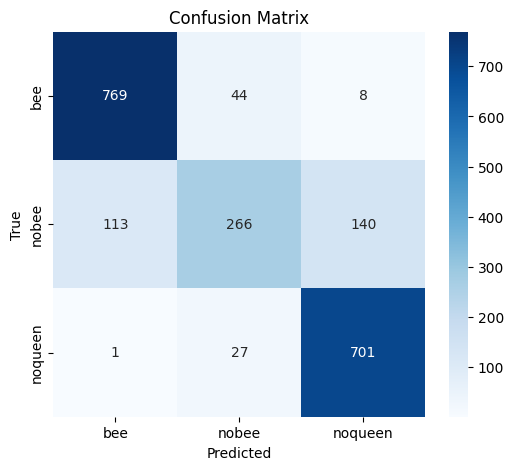

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
test_preds, test_labels = [], []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

# Classification Report
label_names = ["bee", "nobee", "noqueen"]
print("Classification Report:")
print(classification_report(test_labels, test_preds, target_names=label_names))

# Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [7]:
from sklearn.metrics import accuracy_score, f1_score

# Tính toán các chỉ số
test_accuracy = accuracy_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds, average='weighted')

print(f"🎯 Kết quả trên tập Test:")
print(f"   - Accuracy: {test_accuracy:.4f}")
print(f"   - F1 Score (weighted): {test_f1:.4f}")

🎯 Kết quả trên tập Test:
   - Accuracy: 0.8391
   - F1 Score (weighted): 0.8271
